# 1. Data Extraction

In [41]:
# Imports
import os
import pandas as pd
import numpy as np

import json

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import LabelEncoder

mpl.rcParams['figure.figsize'] = (10, 5)
mpl.rcParams['axes.grid'] = False


In [42]:
update_files = False

In [43]:
# global ModBus1_info,ModBus15_info,ModBus1_units,ModBus15_units,ModBus1_address
# global ModBus15_address,ModBus1_UnitDivision,ModBus15_UnitDivision,ADC_info

ModBus1_info = ['Z-Axis RMS Velocity(in/sec)','Z-Axis RMS Velocity(mm/sec)','Temperature(DegF)','Temperature(DegC)','X-Axis RMS Velocity(in/sec)',
                'X-Axis RMS Velocity(mm/sec)','Z-Axis Peak Acceleration(G)','X-Axis Peak Acceleration(G)','Z-Axis Peak Velocity Component Frequency(Hz)','X-Axis Peak Velocity Component Frequency(Hz)',
                'Z-Axis RMS Acceleration(G)','X-Axis RMS Acceleration(G)','Z-Axis Kurtosis','X-Axis Kurtosis','Z-Axis Crest Factor',
                'X-Axis Crest Factor','Z-Axis Peak Velocity(in/sec)', 'Z-Axis Peak Velocity(mm/sec)','X-Axis Peak Velocity(in/sec)', 'X-Axis Peak Velocity(mm/sec)',
                'Z-Axis High-Frequency RMS Acceleration(G)','Z-Axis High-Frequency RMS Acceleration(G)']

ModBus15_info = ['RMS Voltage L1(Volts)','RMS Voltage L2(Volts)','RMS Voltage L3(Volts)','RMS Current L1(Amps)','RMS Current L2(Amps)',
                'RMS Current L3(Amps)','Phase Shift L1(Degrees)','Phase Shift L2(Degrees)','Phase Shift L3(Degrees)','Frequency L1 Current(Hz)',
                'Frequency L2 Current','Frequency L3 Current(Hz)','Frequency L1 Voltage(Hz)','Frequency L1 Voltage(Hz)','Frequency L1 Voltage(Hz)',
                '15V sense','VIN sense']

ModBus1_units = ['in/sec','mm/sec','DegF','DegC','in/sec',
                'mm/sec','G','G','Hz','Hz',
                'G','G','Kurtosis','Kurtosis','Crest Factor',
                'Crest Factor','in/sec','mm/sec','in/sec','mm/sec',
                'G','G']

ModBus15_units = ['volts','volts','volts','Amps','Amps',
                'Amps','Degrees','Degrees','Degrees','Hz',
                'Hz','Hz','Hz','Hz','Hz',
                'millivolts','millivolts']

ADC_info = ['GND','Temp1(DegC)','Temp2(DegC)','Temp3(DegC)','NAN',
                'NAN','NAN','NAN','NAN','NAN',
                'NAN','NAN','NAN','NAN','NAN']

ModBus1_address = ["405201", "405202", "405203", "405204", "405205", 
                   "405206", "405207", "405208", "405209", "405210", 
                   "405211", "405212", "405213", "405214", "405215", 
                   "405216", "405217", "405218", "405219", "405220",
                     "405221", "405222"]

ModBus15_address = ["300001", "300002", "300003", "300004", "300005", 
                   "300006", "300007", "300008", "300009", "300010", 
                   "300011", "300012", "300013", "300014", "300015",
                     "300016", "300017"]

ModBus1_UnitDivision = [10000,1000,100,100,10000,
                        1000,1000,1000,10,10,
                        1000,1000,1000,1000,1000,
                        1000,10000,1000,10000,1000,
                        1000,1000]

ModBus15_UnitDivision = [100,100,100,100,100,
                        100,100,100,100,100,
                        100,100,100,100,100,
                        1,1]


In [44]:
def access_dir(data_sub_dir, data_dir):
    """
    Function is to generate dataset directory path based on the user defined process setting
    This is the primary acquired data directory (raw) 
    :param data_sub_dir # Choose the sub folder to get access to the desired dataset
    :param data_dir: # Choose the end directory containing desired data  
    :return: directory to access data
    """
    # get current directory
    currentpath = os.getcwd()
    # get parent data directory
    data_par_dir = os.path.abspath(os.path.join(currentpath, os.pardir))
    
    # Get the path to image dataset based on choices    
    d_dir = os.path.join(data_par_dir, (data_sub_dir + "/" + data_dir))
    
    return d_dir

def read_json_file(file):
    with open(file, "r") as r:
        response = r.read()
        response = response.replace('\n', '')
        response = response.replace('}{', '},{')
        response = "[" + response + "]"
        return json.loads(response)


def get_sensor_measurements(JSONLog,ADCSelect,ModBus1Select,ModBus15Select):
    
    # For each measurment sample, desired parameters are extracted with its corresponding units
    # selection of parameter is possible with user inputs
    ModBus1_val = []
    ModBus15_val = []
    ADCvalue = []
    
    # additional info
    ModBus1_unitsSelect =[]
    ModBus15_unitsSelect =[]
    ADC_unitSelect = []
    
    # get the time stamp for the measurements
    TimeStamp = JSONLog.get('timeStamp')[:-7]

    # get ADC sensor values
    if len(ADCSelect) == 1:
        ADCvalue = JSONLog.get('sensors').get('adc')[ADCSelect[0]]
        #ADC_unitSelect = ['DegC']
    else:
        for ADCIter in ADCSelect:
            ADCvalue.append(JSONLog.get('sensors').get('adc')[ADCIter])
            #ADC_unitSelect.append('DegC')
    
    # get ModBus sensor values - channel 1
    if len(ModBus1Select) == 1:
        ModBus1_tempval = JSONLog.get('sensors').get('modbus').get('1').get(ModBus1Select[0])        
        ModBus1_val.append(ModBus1_tempval/ModBus1_UnitDivision[ModBus1_address.index(ModBus1Select[0])])
        #ModBus1_unitsSelect.append(ModBus1_units[ModBus1_address.index(ModBus1Select[0])])
    
    else:
        for busIter in ModBus1Select:            
            ModBus1_tempval = JSONLog.get('sensors').get('modbus').get('1').get(busIter)
            ModBus1_val.append(ModBus1_tempval/ModBus1_UnitDivision[ModBus1_address.index(busIter)])  
            #ModBus1_unitsSelect.append(ModBus1_units[ModBus1_address.index(busIter)])
    
    # get ModBus sensor values - channel 15
    if len(ModBus15Select) == 1:
        ModBus15_tempval = JSONLog.get('sensors').get('modbus').get('15').get(ModBus15Select[0])        
        ModBus15_val.append(ModBus15_tempval/ModBus15_UnitDivision[ModBus1_address.index(ModBus15Select[0])])
        #ModBus15_unitsSelect.append(ModBus15_units[ModBus1_address.index(ModBus15Select[0])])
    else:
        for busIter in ModBus15Select:            
            ModBus15_tempval = JSONLog.get('sensors').get('modbus').get('15').get(busIter)
            ModBus15_val.append(ModBus15_tempval/ModBus15_UnitDivision[ModBus15_address.index(busIter)])
            #ModBus15_unitsSelect.append(ModBus15_units[ModBus15_address.index(busIter)]) 
    
    return ADCvalue,ModBus1_val,ModBus15_val,TimeStamp


def extractFeatures_toCSV(dataPath,dataSample,ADCSelect,ModBus1Select,ModBus15Select):

    # Extract individual features and save them as csv
    # Load the first json file for extracting available signals/feature list
    JsonF = os.path.join((dataPath+ "/") + dataSample)
    JsonF = read_json_file(file=JsonF)   

    # get the choosen parameter details
    #ModBus1_unitsSelected = [ModBus1_units[ModBus1_address.index(i)] for i in ModBus1Select]
    #ModBus15_unitsSelected = [ModBus15_units[ModBus15_address.index(i)] for i in ModBus15Select]
    ModBus1_infoSelected = [ModBus1_info[ModBus1_address.index(i)] for i in ModBus1Select]
    ModBus15_infoSelected = [ModBus15_info[ModBus15_address.index(i)] for i in ModBus15Select]
    ADC_infoSelected = [ADC_info[i] for i in ADCSelect]

    timeD = []
    ADCval = []
    Mod1val = []
    Mod15val = []

    # gather sensor measurements
    for i in range(len(JsonF)):
        JSONLog = JsonF[i]      
        # check if all the registers are logged for each measurments.
        # otherwise skip them for adding to the log
        # some measurements does not include all the registers for some reason
        if all(key in JSONLog['sensors']['modbus']['1'].keys() for key in ModBus1Select):
            if all(key in JSONLog['sensors']['modbus']['15'].keys() for key in ModBus15Select):
                A,B,C,D = get_sensor_measurements(JSONLog,ADCSelect,ModBus1Select,ModBus15Select)
        else:
            continue
        
        # append each measurement in a list
        timeD.append(D)
        ADCval.append(np.round(A,2))
        Mod1val.append(B)
        Mod15val.append(C)

    # create a pandas dataframe for all the measurements
    df = pd.DataFrame(ADCval, columns = [ADC_infoSelected]) 
    df[ModBus1_infoSelected] = Mod1val
    df[ModBus15_infoSelected] = Mod15val
    df.insert (0,'TimeStamp',timeD)
    
    # returns JSON object as a dictionary      
    return df

def get_state(to_process_data, df):
    # add colomn for machine state
    if 'Normal' in to_process_data or 'normal' in to_process_data:
        df['machine_state'] = 'normal'
    elif 'misalign' in to_process_data:
        df['machine_state'] = 'misalign'
    else:
        df['machine_state'] = 'unknown'

In [45]:
def process_file(folder_name, file_name, result_dir='analysis'):
    """
    Function to process the data
    :param folder_name: the folder to process
    :param file_name: the file to process
    :param result_dir: the directory to save the results
    :return: 
    """
    print(f"Currently working on file: {file_name}")
    
    # get the readings from the data
    df = extractFeatures_toCSV(f'data/{folder_name}', file_name, ADCSelect, ModBus1Select, ModBus15Select)
    # add column for machine state
    get_state(file_name, df)
    
    # save the processed data
    save_name_csv = f'{result_dir}/processed/{folder_name}/{file_name[:-4]}.csv'
    save_name_image = f'{result_dir}/graph_representation/{folder_name}/{file_name[:-4]}.png'
    save_name_histogram = f'{result_dir}/histogram/{folder_name}/{file_name[:-4]}.png'
    
    df.to_csv(save_name_csv, index=False)
    
    df = pd.read_csv(save_name_csv, parse_dates=True)

    df['Time(sec)'] = df.index*6
    df[100:].plot.line(x='Time(sec)',figsize=(20, 25), subplots=True)
    plt.savefig(save_name_image)
    
    df.hist(layout=(8, 5), figsize=(20, 20), sharey=False, sharex=False, bins=50,grid=False)
    plt.savefig(save_name_histogram)
    
    plt.close('all')

def process_folder(folder_name, result_dir='analysis'):
    """
    Function to process the data
    :param folder_name: the folder to process
    :param result_dir: the directory to save the results
    :return: 
    """
    # get every file in the folder
    files = [f for f in os.listdir(f'data/{folder_name}') if not f.startswith('.')]
    
    # create a folder to save the processed data
    os.mkdir(f'{result_dir}/processed/{folder_name}')
    os.mkdir(f'{result_dir}/graph_representation/{folder_name}')
    os.mkdir(f'{result_dir}/histogram/{folder_name}')
    
    # process the files
    for file in files:
        process_file(folder_name, file, result_dir)
    
def process_data(d, r):
    """
    Function to process the data folders in the given directory
    :param d: the directory to with data folders
    :param r: the directory to save the data
    """
    # get all the folders in the directory
    folders = [f for f in os.listdir(d) if not f.startswith('.')]
    
    # create a folder to save the processed data
    os.system(f'rm -rf {r}')
    os.mkdir(r)
    os.mkdir(r + '/processed')
    os.mkdir(r + '/graph_representation')
    os.mkdir(r + '/histogram')
    
    # process the data in the folders
    for folder in folders:
        print(f"Currently working on folder: {folder}")
        process_folder(folder)
        
    
    
        
    

In [46]:
ModBus1Select = ModBus1_address  #["405202","405204", "405206","405209","405210","405211","405212","405221","405222"] # ModBus1_address 
ModBus15Select = ModBus15_address # ["300001", "300004","300007","300010","300013"] #ModBus15_address
ADCSelect = []

if update_files:
    process_data('data', 'analysis')

# 2. Dataset Preparation

In [47]:
# create a complete df with all the data
def create_dataset(source):
    if not os.path.exists('datasets'):
        os.mkdir('datasets')
        
    folders = [f for f in os.listdir(f'{source}/processed') if not f.startswith('.')]
    df = pd.DataFrame()
    for folder in folders:
        files = [f for f in os.listdir(f'{source}/processed/{folder}') if not f.startswith('.')]
        for file in files:
            temp_df = pd.read_csv(f'{source}/processed/{folder}/{file}')
            df = pd.concat([df, temp_df], ignore_index=True)
            
    df = df.drop(columns=['TimeStamp'])
    df['Time(sec)'] = df.index*6
    df_no_freq = df.drop(columns=['Frequency L1 Current(Hz)', 'Frequency L2 Current', 'Frequency L3 Current(Hz)', 'Frequency L1 Voltage(Hz)'])
    return df, df_no_freq
    
    

In [48]:
# create a complete df with all the data
dataset_name = 'complete'
df, df_no_freq = create_dataset('analysis')

In [49]:
df['Time(sec)'] = df.index*6
df_no_freq['Time(sec)'] = df_no_freq.index*6

In [50]:
label_encoder = LabelEncoder()
df['machine_state'] = label_encoder.fit_transform(df['machine_state'])

df_no_freq['machine_state'] = label_encoder.fit_transform(df_no_freq['machine_state'])


In [51]:
df.groupby('machine_state')['Frequency L2 Current'].value_counts().unstack().fillna(0)

Frequency L2 Current,0.5,1.0,1.5,2.0,2.5,3.0,3.5,6.5,7.0,7.5,...,18.0,18.5,19.0,19.5,20.0,20.5,24.5,25.0,30.0,35.0
machine_state,,,,,,,,,,,,,,,,,,,,,
0,183.0,254.0,204.0,7.0,32.0,162.0,66.0,2.0,6.0,8.0,...,1.0,1.0,0.0,0.0,872.0,0.0,1.0,6608.0,589.0,45.0
1,11.0,12.0,13.0,0.0,0.0,6.0,1.0,0.0,1.0,0.0,...,1.0,0.0,3.0,4.0,462.0,1.0,0.0,3325.0,1161.0,0.0


In [52]:
# print percentage of normal and faulty data
df['machine_state'].value_counts(normalize=True)

machine_state
0    0.67222
1    0.32778
Name: proportion, dtype: float64

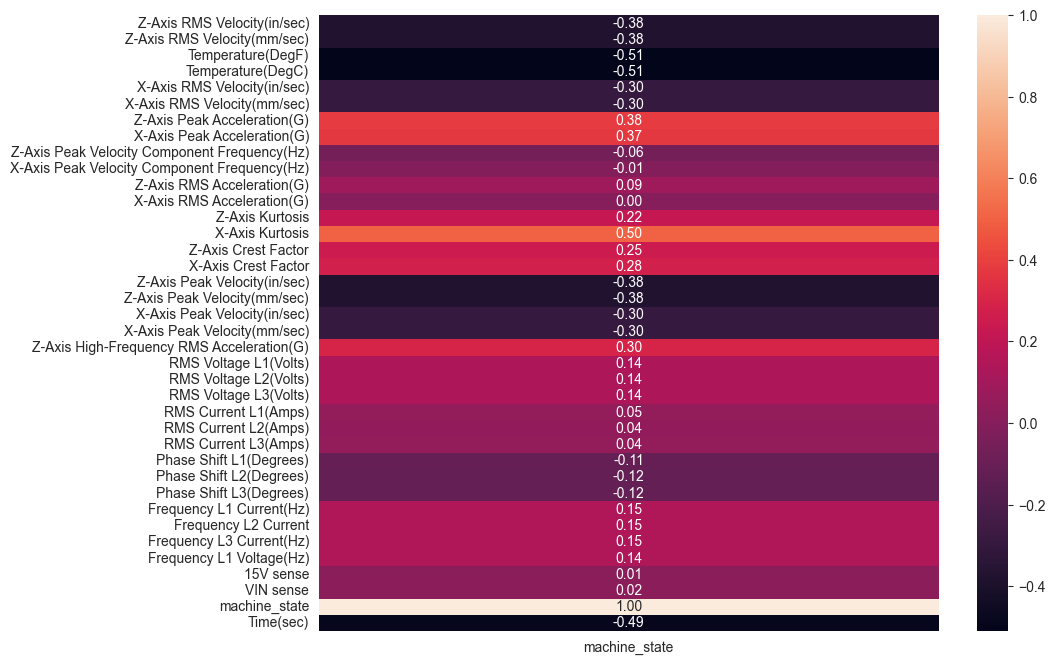

In [53]:
#correlation matrix only for machine state
corr_matrix = df.corr()
corr_matrix['machine_state'].sort_values(ascending=False)
# plot the correlation matrix with only machine state
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix[['machine_state']], annot=True, fmt=".2f")
plt.show()



In [54]:
# remove any entry with Frequency L2 Current lower than 10
df = df[df['Frequency L2 Current'] >= 10]

# new feature multiply frequency with temperature
df['Frequency_L2_Current_Temperature'] = df['Frequency L2 Current'] / df['Temperature(DegC)']
df['Frequency_L2_Z_Axis_Peak_Acceleration'] = df['Z-Axis Peak Acceleration(G)'] / df['Frequency L2 Current']

label_encoder = LabelEncoder()
df['machine_state'] = label_encoder.fit_transform(df['machine_state'])
df.to_csv(f'datasets/{dataset_name}.csv', index=False)

df_no_freq['machine_state'] = label_encoder.fit_transform(df_no_freq['machine_state'])
df_no_freq.to_csv(f'datasets/{dataset_name}_no_freq.csv', index=False)

# 3. Data Preprocessing and Model Building

In [59]:
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Models
from sklearn.ensemble import GradientBoostingClassifier

from torch import nn
import torch
from torch.optim import Adam, SGD
from torch.utils.data import DataLoader

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

import shap # for SHAP values

In [70]:
df = pd.read_csv('datasets/complete.csv')
# df_no_freq = pd.read_csv('datasets/complete_no_freq.csv')

print(f"Shape of df: {df.shape}\n")

Shape of df: (25558, 40)



In [62]:
# split the data
X_GDC = df[['Z-Axis Peak Velocity(mm/sec)', 'X-Axis Kurtosis', 'Frequency_L2_Current_Temperature', 'Frequency_L2_Z_Axis_Peak_Acceleration']].values
X_GDC_no_freq = df_no_freq[['Z-Axis Peak Velocity(mm/sec)', 'X-Axis Kurtosis']].values
X_FF = df.drop(columns='machine_state').values
X_FF_no_freq = df_no_freq.drop(columns='machine_state').values

y_GDC = df['machine_state'].values
y_GDC_no_freq = df_no_freq['machine_state'].values
y_FF = df['machine_state'].values
y_FF_no_freq = df_no_freq['machine_state'].values

In [63]:
# scale the data
scaler = StandardScaler()
X_GDC = scaler.fit_transform(X_GDC)
X_GDC_no_freq = scaler.fit_transform(X_GDC_no_freq)
X_FF = scaler.fit_transform(X_FF)
X_FF_no_freq = scaler.fit_transform(X_FF_no_freq)

In [64]:
print(f'Before GDC: {X_GDC.shape}\nBefore GDC no freq: {X_GDC_no_freq.shape}\nBefore FF: {X_FF.shape}\nBefore FF no freq: {X_FF_no_freq.shape}')

Before GDC: (25558, 4)
Before GDC no freq: (26530, 2)
Before FF: (25558, 39)
Before FF no freq: (26530, 33)


In [66]:
# outlier removal
outlier_remover = IsolationForest(contamination=0.1)
outliers_GDC = outlier_remover.fit_predict(X_GDC)
outliers_GDC_no_freq = outlier_remover.fit_predict(X_GDC_no_freq)
outliers_FF = outlier_remover.fit_predict(X_FF)
outliers_FF_no_freq = outlier_remover.fit_predict(X_FF_no_freq)

X_GDC = X_GDC[outliers_GDC == 1]
X_GDC_no_freq = X_GDC_no_freq[outliers_GDC_no_freq == 1]
X_FF = X_FF[outliers_FF == 1]
X_FF_no_freq = X_FF_no_freq[outliers_FF_no_freq == 1]

y_GDC = y_GDC[outliers_GDC == 1]
y_GDC_no_freq = y_GDC_no_freq[outliers_GDC_no_freq == 1]
y_FF = y_FF[outliers_FF == 1]
y_FF_no_freq = y_FF_no_freq[outliers_FF_no_freq == 1]

print(f'After GDC: {X_GDC.shape}\nAfter GDC no freq: {X_GDC_no_freq.shape}\nAfter FF: {X_FF.shape}\nAfter FF no freq: {X_FF_no_freq.shape}')


After GDC: (23002, 4)
After GDC no freq: (23877, 2)
After FF: (23002, 39)
After FF no freq: (23877, 33)


In [69]:
# check the amount of the data for each frequency

temp['Frequency L2 Current'].value_counts()

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [21]:
X_GDC_train, X_GDC_test, y_GDC_train, y_GDC_test = train_test_split(X_GDC, y_GDC, test_size=0.2, random_state=42)
X_GDC_no_freq_train, X_GDC_no_freq_test, y_GDC_no_freq_train, y_GDC_no_freq_test = train_test_split(X_GDC_no_freq, y_GDC_no_freq, test_size=0.2, random_state=42)
X_FF_train, X_FF_test, y_FF_train, y_FF_test = train_test_split(X_FF, y_FF, test_size=0.2, random_state=42)
X_FF_no_freq_train, X_FF_no_freq_test, y_FF_no_freq_train, y_FF_no_freq_test = train_test_split(X_FF_no_freq, y_FF_no_freq, test_size=0.2, random_state=42)

In [22]:
# print balance of test
print(f"Balance of GDC test:\n{pd.Series(y_GDC_test).value_counts(normalize=True)}\n")
print(f"Balance of GDC no freq test:\n{pd.Series(y_GDC_no_freq_test).value_counts(normalize=True)}\n")
print(f"Balance of FF test:\n{pd.Series(y_FF_test).value_counts(normalize=True)}\n")
print(f"Balance of FF no freq test:\n{pd.Series(y_FF_no_freq_test).value_counts(normalize=True)}\n")

Balance of GDC test:
0    0.670289
1    0.329711
Name: proportion, dtype: float64

Balance of GDC no freq test:
0    0.671901
1    0.328099
Name: proportion, dtype: float64

Balance of FF test:
0    0.680287
1    0.319713
Name: proportion, dtype: float64

Balance of FF no freq test:
0    0.673157
1    0.326843
Name: proportion, dtype: float64



In [23]:
# print balance of all the datasets
print(f"Balance of GDC:\n{pd.Series(y_GDC_train).value_counts(normalize=True)}\n")
print(f"Balance of GDC no freq:\n{pd.Series(y_GDC_no_freq_train).value_counts(normalize=True)}\n")
print(f"Balance of FF:\n{pd.Series(y_FF_train).value_counts(normalize=True)}\n")
print(f"Balance of FF no freq:\n{pd.Series(y_FF_no_freq_train).value_counts(normalize=True)}\n")


Balance of GDC:
0    0.665616
1    0.334384
Name: proportion, dtype: float64

Balance of GDC no freq:
0    0.670122
1    0.329878
Name: proportion, dtype: float64

Balance of FF:
0    0.678822
1    0.321178
Name: proportion, dtype: float64

Balance of FF no freq:
0    0.677085
1    0.322915
Name: proportion, dtype: float64



In [24]:
# smote
smote = SMOTE(random_state=42)
X_GDC_train_smote, y_GDC_train_smote = smote.fit_resample(X_GDC_train, y_GDC_train)
X_GDC_no_freq_train_smote, y_GDC_no_freq_train_smote = smote.fit_resample(X_GDC_no_freq_train, y_GDC_no_freq_train)
X_FF_train_smote, y_FF_train_smote = smote.fit_resample(X_FF_train, y_FF_train)
X_FF_no_freq_train_smote, y_FF_no_freq_train_smote = smote.fit_resample(X_FF_no_freq_train, y_FF_no_freq_train)

In [25]:
# print balance of all the datasets
print(f"Balance of GDC after SMOTE:\n{pd.Series(y_GDC_train_smote).value_counts(normalize=True)}\nShape: {X_GDC_train_smote.shape}\n")
print(f"Balance of GDC no freq after SMOTE:\n{pd.Series(y_GDC_no_freq_train_smote).value_counts(normalize=True)}\nShape: {X_GDC_no_freq_train_smote.shape}\n")
print(f"Balance of FF after SMOTE:\n{pd.Series(y_FF_train_smote).value_counts(normalize=True)}\nShape: {X_FF_train_smote.shape}\n")
print(f"Balance of FF no freq after SMOTE:\n{pd.Series(y_FF_no_freq_train_smote).value_counts(normalize=True)}\nShape: {X_FF_no_freq_train_smote.shape}\n")


Balance of GDC after SMOTE:
0    0.5
1    0.5
Name: proportion, dtype: float64
Shape: (24496, 4)

Balance of GDC no freq after SMOTE:
0    0.5
1    0.5
Name: proportion, dtype: float64
Shape: (25600, 2)

Balance of FF after SMOTE:
0    0.5
1    0.5
Name: proportion, dtype: float64
Shape: (24982, 39)

Balance of FF no freq after SMOTE:
0    0.5
1    0.5
Name: proportion, dtype: float64
Shape: (25866, 33)



In [26]:
# smoteenn
smoteenn = SMOTEENN(random_state=42)
X_GDC_train_smoteenn, y_GDC_train_smoteenn = smoteenn.fit_resample(X_GDC_train, y_GDC_train)
X_GDC_no_freq_train_smoteenn, y_GDC_no_freq_train_smoteenn = smoteenn.fit_resample(X_GDC_no_freq_train, y_GDC_no_freq_train)
X_FF_train_smoteenn, y_FF_train_smoteenn = smoteenn.fit_resample(X_FF_train, y_FF_train)
X_FF_no_freq_train_smoteenn, y_FF_no_freq_train_smoteenn = smoteenn.fit_resample(X_FF_no_freq_train, y_FF_no_freq_train)


In [27]:
# print balance of all the datasets
print(f"Balance of GDC after SMOTEENN:\n{pd.Series(y_GDC_train_smoteenn).value_counts(normalize=True)}\nShape: {X_GDC_train_smoteenn.shape}\n")
print(f"Balance of GDC no freq after SMOTEENN:\n{pd.Series(y_GDC_no_freq_train_smoteenn).value_counts(normalize=True)}\nShape: {X_GDC_no_freq_train_smoteenn.shape}\n")
print(f"Balance of FF after SMOTEENN:\n{pd.Series(y_FF_train_smoteenn).value_counts(normalize=True)}\nShape: {X_FF_train_smoteenn.shape}\n")
print(f"Balance of FF no freq after SMOTEENN:\n{pd.Series(y_FF_no_freq_train_smoteenn).value_counts(normalize=True)}\nShape: {X_FF_no_freq_train_smoteenn.shape}\n")


Balance of GDC after SMOTEENN:
1    0.503238
0    0.496762
Name: proportion, dtype: float64
Shape: (23623, 4)

Balance of GDC no freq after SMOTEENN:
1    0.504345
0    0.495655
Name: proportion, dtype: float64
Shape: (19447, 2)

Balance of FF after SMOTEENN:
1    0.500522
0    0.499478
Name: proportion, dtype: float64
Shape: (24916, 39)

Balance of FF no freq after SMOTEENN:
1    0.500563
0    0.499437
Name: proportion, dtype: float64
Shape: (25755, 33)



In [28]:
# evaluate the model
def evaluate_model(eval_gbc_model, X_train, y_train, X_test, y_test):
    eval_gbc_model.fit(X_train, y_train)
    y_pred = eval_gbc_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    report = classification_report(y_test, y_pred)
    
    print(report)
    print(f'Accuracy: {accuracy}')
    
    plt.figure(figsize=(5, 2))
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel('Predicted')
    plt.ylabel('Truth')
    plt.show()
    

In [29]:
# Gradient Boosting Classifier
model = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=3, random_state=42)

In [30]:
# Feed Forward Model
class FeedForward(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FeedForward, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.5)
        # 
        self.fc2 = nn.Linear(hidden_dim, 32)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.3)

        self.fc3 = nn.Linear(32, output_dim)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu1(out)
        out = self.dropout1(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.dropout2(out)
        out = self.fc3(out)
        out = self.sigmoid(out)
        return out

# early stopping
class EarlyStopping:
    def __init__(self, patience=10, verbose=False, delta=0):
        """
        :param patience: How long to wait after last time validation loss improved.
        :param verbose: If True, prints a message for each validation loss improvement.
        :param delta: Minimum change in the monitored quantity to qualify as an improvement.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0 # counter for the number of epochs with no improvement
        self.best_score = None # the best score so far
        self.early_stop = False # whether to stop the training
        self.val_loss_min = np.Inf # the minimum validation loss
        self.delta = delta

    def __call__(self, val_loss, call_model):
        score = -val_loss # the score is the negative of the validation loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, call_model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, call_model)
            self.counter = 0

    def save_checkpoint(self, val_loss, checkpoint_model):
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model...')
        torch.save(checkpoint_model.state_dict(), 'checkpoint.pt')
        self.val_loss_min = val_loss

In [31]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

In [32]:
# training the feed forward model
def train(X_train, y_train, X_test, y_test, hidden_dimensions = 32, epoch_count = 100, patience=10, lr=0.001, momentum=0.9, weight_decay=0.1, optimization='SGD', show_results=True, debug=False):
    X_train = torch.FloatTensor(X_train)
    y_train = torch.FloatTensor(y_train)
    X_test = torch.FloatTensor(X_test)
    y_test = torch.FloatTensor(y_test)

    y_train = y_train.unsqueeze(1)
    y_test = y_test.unsqueeze(1)

    X_test = X_test.to(device)
    y_test = y_test.to(device)


    train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)

    input_dimensions = X_train.shape[1]
    output_dimensions = 1
    ff_model = FeedForward(input_dimensions, hidden_dimensions, output_dimensions)
    ff_model.to(device)

    criterion = nn.BCELoss()
    if optimization == 'SGD':
        optim = SGD(ff_model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay)
    else:
        optim = Adam(ff_model.parameters(), lr=lr, weight_decay=weight_decay)


    early_stopping = EarlyStopping(patience=patience, verbose=debug)

    losses, accuracies, f1_scores = epochs(epoch_count, ff_model, train_loader, X_test, y_test, criterion, optim, early_stopping)

    training_results(losses, accuracies, f1_scores)

    if show_results:
        eval_model(ff_model, X_test, y_test)

    return ff_model

def epochs(epoch_c, epoch_model, train_loader, X_test, y_test, criterion, optim, early_stopping, debug=False):
    # storing metrics
    losses = []
    accuracies = []
    f1_scores = []

    for epoch in range(epoch_c):
        total_loss = 0
        total = 0

        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            outputs = epoch_model(data)
            loss = criterion(outputs, target)
            total_loss += loss.item()
            total += target.size(0)

            # backpropagation
            optim.zero_grad()
            loss.backward()
            optim.step()

        # validation
        epoch_loss, epoch_acc, epoch_f1 = validate(epoch_model, X_test, y_test, criterion)
        if debug:
            print(f'Epoch: {epoch+1}, Loss: {epoch_loss}, Accuracy: {epoch_acc}, F1 Score: {epoch_f1}')

        # Append metrics to the lists
        losses.append(epoch_loss)
        accuracies.append(epoch_acc)
        f1_scores.append(epoch_f1)

        # early stopping
        early_stopping(epoch_loss, epoch_model)
        if early_stopping.early_stop:
            if debug:
                print('Early stopping has been triggered.')
            break

    return losses, accuracies, f1_scores

def validate(val_model, val_x, val_y, val_criterion):
    val_x = val_x.to(device)
    val_y = val_y.to(device)

    val_model.eval()
    val_total_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        val_outputs = val_model(val_x)
        val_loss = val_criterion(val_outputs, val_y)
        val_total_loss += val_loss.item()

        val_predicted = val_outputs.round()
        val_correct += val_predicted.eq(val_y).sum().item()
        val_total += val_y.size(0)

        val_epoch_loss = val_total_loss / val_total
        val_epoch_acc = val_correct / val_total
        val_epoch_f1 = f1_score(val_y.cpu().numpy(), val_predicted.cpu().numpy())

    return val_epoch_loss, val_epoch_acc, val_epoch_f1

def training_results(losses, accuracies, f1_scores):
    # Plot the metrics
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.plot(losses, label='Loss')
    plt.legend()

    plt.subplot(1, 3, 2)
    plt.plot(accuracies, label='Accuracy')
    plt.legend()

    plt.subplot(1, 3, 3)
    plt.plot(f1_scores, label='F1 Score')
    plt.legend()

    plt.show()

def eval_model(eval_ff_model, X_val, y_val):
    eval_ff_model.eval()
    with torch.no_grad():
        y_pred = eval_ff_model(X_val)
        y_pred = y_pred.round()

    # calculate the accuracy
    y_val = y_val.cpu().numpy()
    y_pred = y_pred.cpu().numpy()
    accuracy = accuracy_score(y_val, y_pred)
    cm = confusion_matrix(y_val, y_pred)
    report = classification_report(y_val, y_pred)

    # print classification report
    print(report)
    print(f'Accuracy: {accuracy}')

    # plot confusion matrix
    plt.figure(figsize=(5, 2))
    sns.heatmap(cm, annot=True, fmt='d')
    plt.xlabel('Predicted')
    plt.ylabel('Truth')
    plt.show()

Gradient Boosting Classifier data containing frequency features with SMOTE
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3084
           1       0.96      0.98      0.97      1517

    accuracy                           0.98      4601
   macro avg       0.98      0.98      0.98      4601
weighted avg       0.98      0.98      0.98      4601

Accuracy: 0.9808737231036732


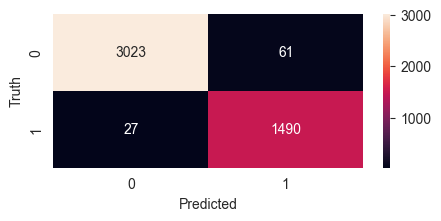

In [33]:
print("Gradient Boosting Classifier data containing frequency features with SMOTE")
evaluate_model(model, X_GDC_train_smote, y_GDC_train_smote, X_GDC_test, y_GDC_test)


Gradient Boosting Classifier data containing frequency features with SMOTEENN
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3084
           1       0.97      0.99      0.98      1517

    accuracy                           0.98      4601
   macro avg       0.98      0.98      0.98      4601
weighted avg       0.98      0.98      0.98      4601

Accuracy: 0.9845685720495544


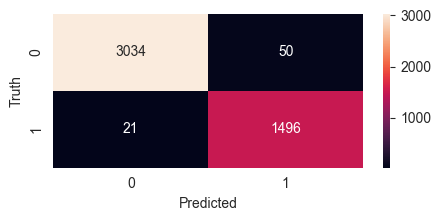

In [34]:
print("Gradient Boosting Classifier data containing frequency features with SMOTEENN")
evaluate_model(model, X_GDC_train_smoteenn, y_GDC_train_smoteenn, X_GDC_test, y_GDC_test)

Gradient Boosting Classifier data without frequency features with SMOTE
              precision    recall  f1-score   support

           0       0.93      0.86      0.89      3209
           1       0.75      0.86      0.80      1567

    accuracy                           0.86      4776
   macro avg       0.84      0.86      0.85      4776
weighted avg       0.87      0.86      0.86      4776

Accuracy: 0.8592964824120602


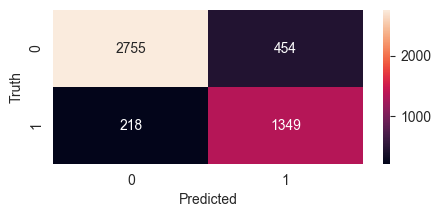

In [35]:
print("Gradient Boosting Classifier data without frequency features with SMOTE")
evaluate_model(model, X_GDC_no_freq_train_smote, y_GDC_no_freq_train_smote, X_GDC_no_freq_test, y_GDC_no_freq_test)

Gradient Boosting Classifier data without frequency features with SMOTEENN
              precision    recall  f1-score   support

           0       0.94      0.86      0.89      3209
           1       0.75      0.88      0.81      1567

    accuracy                           0.86      4776
   macro avg       0.84      0.87      0.85      4776
weighted avg       0.87      0.86      0.87      4776

Accuracy: 0.8639028475711893


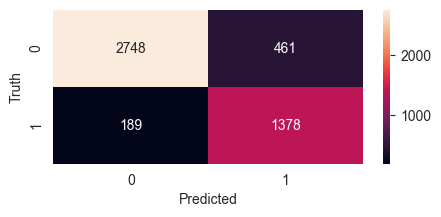

In [36]:
print("Gradient Boosting Classifier data without frequency features with SMOTEENN")
evaluate_model(model, X_GDC_no_freq_train_smoteenn, y_GDC_no_freq_train_smoteenn, X_GDC_no_freq_test, y_GDC_no_freq_test)

Feed Forward Classifier data containing frequency features with SMOTE


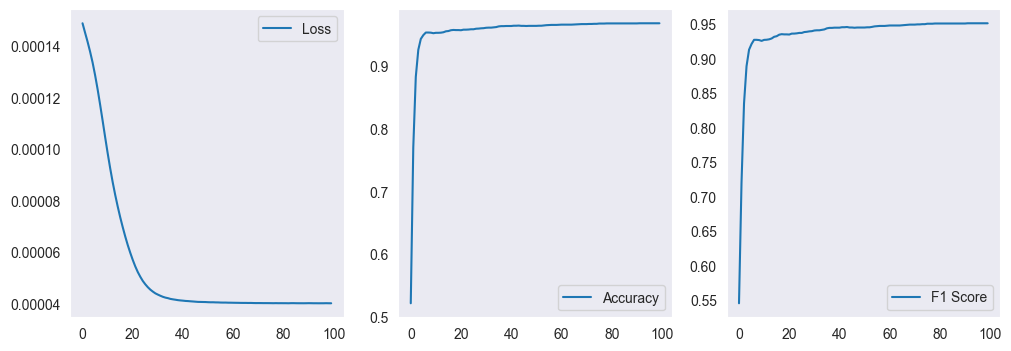

              precision    recall  f1-score   support

         0.0       0.98      0.97      0.98      3130
         1.0       0.95      0.96      0.95      1471

    accuracy                           0.97      4601
   macro avg       0.96      0.96      0.96      4601
weighted avg       0.97      0.97      0.97      4601

Accuracy: 0.9684851119321887


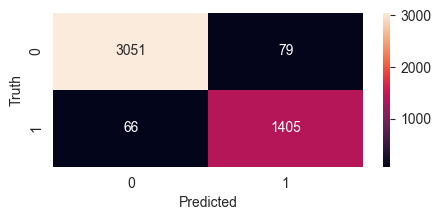

FeedForward(
  (fc1): Linear(in_features=39, out_features=32, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

In [37]:
print("Feed Forward Classifier data containing frequency features with SMOTE")
train(X_FF_train_smote, y_FF_train_smote, X_FF_test, y_FF_test, hidden_dimensions=32, epoch_count=100, patience=10, lr=0.001, momentum=0.9, weight_decay=0.1, optimization='SGD', show_results=True)

Feed Forward Classifier data containing frequency features with SMOTEENN


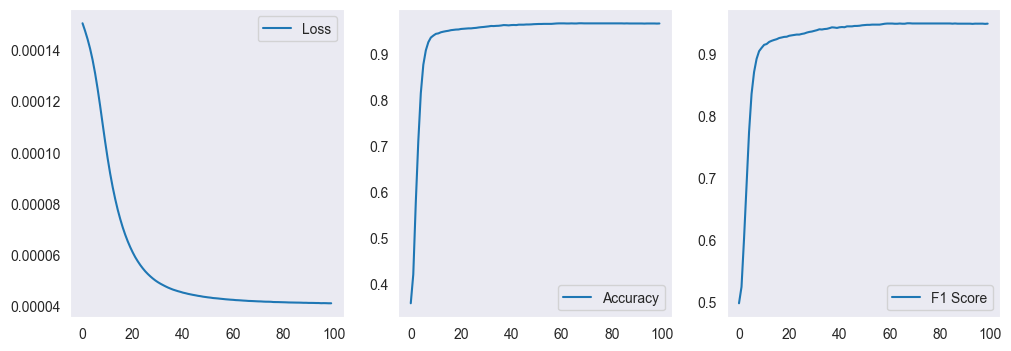

              precision    recall  f1-score   support

         0.0       0.98      0.97      0.98      3130
         1.0       0.94      0.96      0.95      1471

    accuracy                           0.97      4601
   macro avg       0.96      0.96      0.96      4601
weighted avg       0.97      0.97      0.97      4601

Accuracy: 0.966746359487068


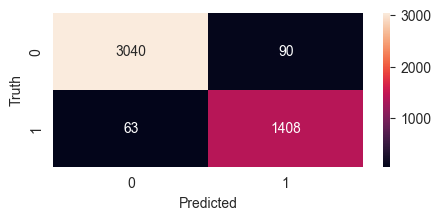

FeedForward(
  (fc1): Linear(in_features=39, out_features=32, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

In [38]:
print("Feed Forward Classifier data containing frequency features with SMOTEENN")
train(X_FF_train_smoteenn, y_FF_train_smoteenn, X_FF_test, y_FF_test, hidden_dimensions=32, epoch_count=100, patience=10, lr=0.001, momentum=0.9, weight_decay=0.1, optimization='SGD', show_results=True)

Feed Forward Classifier data without frequency features with SMOTE


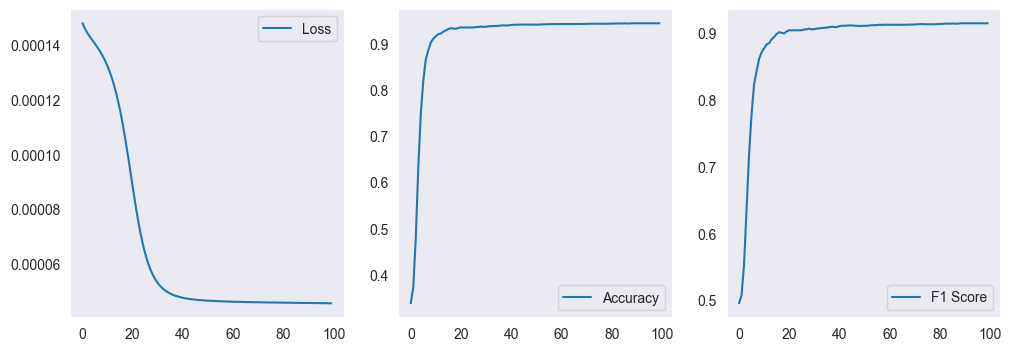

              precision    recall  f1-score   support

         0.0       0.95      0.96      0.96      3215
         1.0       0.92      0.91      0.91      1561

    accuracy                           0.94      4776
   macro avg       0.94      0.93      0.94      4776
weighted avg       0.94      0.94      0.94      4776

Accuracy: 0.9449329983249581


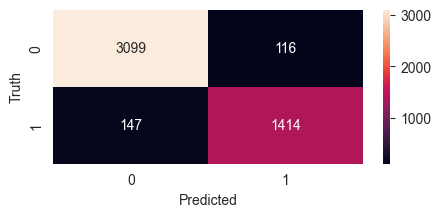

FeedForward(
  (fc1): Linear(in_features=33, out_features=32, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

In [39]:
print("Feed Forward Classifier data without frequency features with SMOTE")
train(X_FF_no_freq_train_smote, y_FF_no_freq_train_smote, X_FF_no_freq_test, y_FF_no_freq_test, hidden_dimensions=32, epoch_count=100, patience=10, lr=0.001, momentum=0.9, weight_decay=0.1, optimization='SGD', show_results=True)

Feed Forward Classifier data without frequency features with SMOTEENN


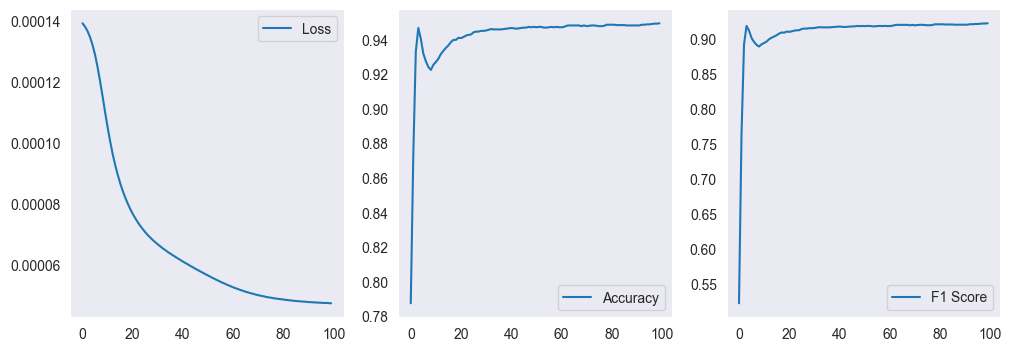

              precision    recall  f1-score   support

         0.0       0.96      0.96      0.96      3215
         1.0       0.92      0.92      0.92      1561

    accuracy                           0.95      4776
   macro avg       0.94      0.94      0.94      4776
weighted avg       0.95      0.95      0.95      4776

Accuracy: 0.9495393634840871


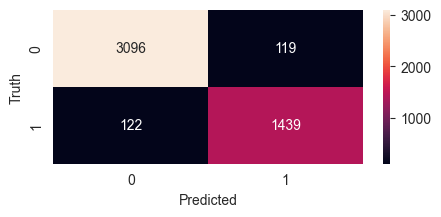

FeedForward(
  (fc1): Linear(in_features=33, out_features=32, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

In [40]:
print("Feed Forward Classifier data without frequency features with SMOTEENN")
train(X_FF_no_freq_train_smoteenn, y_FF_no_freq_train_smoteenn, X_FF_no_freq_test, y_FF_no_freq_test, hidden_dimensions=32, epoch_count=100, patience=10, lr=0.001, momentum=0.9, weight_decay=0.1, optimization='SGD', show_results=True)